In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt

from src.config import DATA_DIR, MANIFEST_PATH, SPLIT_MANIFEST_PATH, SEED
from src.dataset import build_manifest, split_manifest

print("Buscando el dataset en:", DATA_DIR)

Buscando el dataset en: /home/kevin/Documentos/Django/Mango/mango


# 1. Crear el manifiesto

In [2]:
manifest = build_manifest(DATA_DIR)

print(f"Total de imágenes encontradas: {len(manifest)}")

manifest.head()

Total de imágenes encontradas: 975


,filepath,filename,label_name,label
0,/home/kevin/Documentos/Django/Mango/mango/Over...,GUTI_138_A.jpg,OverRipe,0
1,/home/kevin/Documentos/Django/Mango/mango/Over...,GUTI_138_B.jpg,OverRipe,0
2,/home/kevin/Documentos/Django/Mango/mango/Over...,GUTI_164_A.jpg,OverRipe,0
3,/home/kevin/Documentos/Django/Mango/mango/Over...,GUTI_164_B.jpg,OverRipe,0
4,/home/kevin/Documentos/Django/Mango/mango/Over...,GUTI_169_A.jpg,OverRipe,0


In [3]:
print("Imágenes por clase:")

print(manifest["label_name"].value_counts())

Imágenes por clase:
label_name
UnRipe      911
Ripe         43
OverRipe     21
Name: count, dtype: int64


# 2. Gráfico del balance

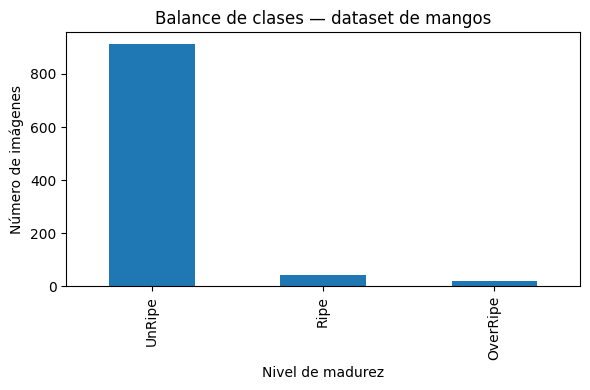

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))

manifest["label_name"].value_counts().plot(
    kind="bar",
    ax=ax
)

ax.set_title("Balance de clases — dataset de mangos")
ax.set_ylabel("Número de imágenes")
ax.set_xlabel("Nivel de madurez")

plt.tight_layout()
plt.show()

# 3. Revisar tamaños de imágenes

In [5]:
from PIL import Image

widths = []
heights = []

for path in manifest["filepath"]:
    try:
        with Image.open(path) as img:
            widths.append(img.width)
            heights.append(img.height)
    except Exception as e:
        widths.append(None)
        heights.append(None)

manifest["width"] = widths
manifest["height"] = heights

manifest[["width", "height"]].describe()

,width,height
count,975.000000,975.000000
mean,799.977436,799.917949
std,0.704564,1.824833
min,778.000000,755.000000
25%,800.000000,800.000000
50%,800.000000,800.000000
75%,800.000000,800.000000
max,800.000000,800.000000


In [6]:
print("Tamaños más frecuentes:")

print(
    manifest
    .groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
    .head(10)
)

Tamaños más frecuentes:
width  height
800    800       972
778    800         1
800    755         1
       765         1
dtype: int64


# 4. Revisar imágenes por clase

In [7]:
print(manifest.groupby("label_name").size())

label_name
OverRipe     21
Ripe         43
UnRipe      911
dtype: int64


In [8]:
porcentajes = (
    manifest["label_name"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(porcentajes)

label_name
UnRipe      93.44
Ripe         4.41
OverRipe     2.15
Name: proportion, dtype: float64


# 5.Crear el Split

In [9]:
from src.dataset import split_manifest_por_mango

split = split_manifest_por_mango(manifest)

print(split.groupby(["split", "label_name"]).size())

split  label_name
test   OverRipe        5
       Ripe            8
       UnRipe        139
train  OverRipe       14
       Ripe           29
       UnRipe        636
val    OverRipe        2
       Ripe            6
       UnRipe        136
dtype: int64


In [10]:
verificar = split.assign(mango_id=split["filename"].str.rsplit("_", n=1).str[0])
repartidos = verificar.groupby(["label_name", "mango_id"])["split"].nunique()

print("Mangos repartidos en más de un split:", int((repartidos > 1).sum()))

Mangos repartidos en más de un split: 0


# 6.Guardar los Manifest

In [11]:
from src.config import MANIFEST_PATH, SPLIT_MANIFEST_PATH

MANIFEST_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

manifest.to_csv(
    MANIFEST_PATH,
    index=False
)

split.to_csv(
    SPLIT_MANIFEST_PATH,
    index=False
)

print("Guardado:")
print("-", MANIFEST_PATH)
print("-", SPLIT_MANIFEST_PATH)

Guardado:
- /home/kevin/Documentos/Django/Mango/data/processed/manifest.csv
- /home/kevin/Documentos/Django/Mango/data/processed/manifest_split.csv
